# Exercice 2 — Similarité basée sur les histogrammes de couleur

## Objectif

Représenter chaque image du dossier `seance 4/Couleur/` par ses **histogrammes de couleur normalisés**, puis mesurer la similarité entre images avec l'**intersection d'histogrammes**.

## Principe

Un histogramme de couleur décrit la **distribution** des couleurs dans l'image : combien de pixels ont telle intensité dans chaque canal. Contrairement à l'exercice 1 qui ne gardait que quelques couleurs dominantes, on conserve ici **toute la distribution**.

Deux images se ressemblent si leur distribution de couleurs se superpose. L'**intersection** de deux histogrammes mesure exactement cette zone commune.

## Plan du notebook

| Étape | Contenu |
|---|---|
| 1 | Masque du fond (repris de l'exercice 1) |
| 2 | Calcul des histogrammes RGB normalisés |
| 3 | Intersection d'histogrammes |
| 4 | Matrice de similarité |
| 5 | Visualisation et comparaison avec l'exercice 1 |
| 6 | Analyse et discussion |


In [1]:
import os
import glob
import csv

import numpy as np
import cv2
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------------
# Configuration (identique à l'exercice 1)
# ---------------------------------------------------------------------------
# Le notebook fonctionne que le dossier courant soit "seance 4" ou la racine.
BASE = "seance 4" if os.path.isdir("seance 4") else "."

DOSSIER_IMAGES = os.path.join(BASE, "Couleur")
DOSSIER_RESULTATS = os.path.join(BASE, "resultats")
os.makedirs(DOSSIER_RESULTATS, exist_ok=True)

# Paramètres de la méthode
BINS = 32                # nombre de bins par canal (3 canaux -> 96 valeurs)
TOLERANCE_FOND = 20      # tolérance de distance RGB pour le masque du fond

# Liste des images
chemins = sorted(glob.glob(os.path.join(DOSSIER_IMAGES, "*.png")))
noms_images = [os.path.basename(c) for c in chemins]

print(f"{len(chemins)} images trouvées dans '{DOSSIER_IMAGES}' :")
for nom in noms_images:
    print("   -", nom)


12 images trouvées dans '.\Couleur' :
   - obj14__275.png
   - obj14__330.png
   - obj14__60.png
   - obj16__245.png
   - obj16__5.png
   - obj16__70.png
   - obj1__180.png
   - obj1__40.png
   - obj1__95.png
   - obj27__125.png
   - obj27__190.png
   - obj27__275.png


## Étape 1 — Masque du fond

Comme pour l'exercice 1, les 12 images partagent un **fond sombre commun** (≈ `[25, 25, 25]`). Ce fond occupe entre 17 % et 76 % de l'image selon la vue : s'il n'est pas retiré, toutes les images paraîtront similaires à cause de ce grand pic sombre identique dans les histogrammes.

On réutilise **exactement la même méthode** que dans l'exercice 1, ce qui garantit que la comparaison entre les deux exercices est équitable :

1. La couleur du fond est la couleur la plus fréquente sur la **bordure** de l'image.
2. Un pixel est un pixel d'objet si sa distance RGB au fond est **supérieure à 20**.


In [2]:
def charger_image(chemin):
    """Charge une image avec OpenCV et la convertit en RGB (OpenCV lit en BGR)."""
    bgr = cv2.imread(chemin)
    if bgr is None:
        raise FileNotFoundError(f"Image introuvable : {chemin}")
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


def couleur_fond(rgb):
    """Estime la couleur du fond : couleur la plus fréquente sur la bordure."""
    bordure = np.concatenate([rgb[0, :], rgb[-1, :], rgb[:, 0], rgb[:, -1]])
    valeurs, comptes = np.unique(bordure.reshape(-1, 3), axis=0, return_counts=True)
    return valeurs[np.argmax(comptes)]


def masque_objet(rgb, tolerance=TOLERANCE_FOND):
    """Masque booléen : True pour les pixels d'objet (éloignés de la couleur du fond)."""
    fond = couleur_fond(rgb)
    distance = np.linalg.norm(rgb.astype(float) - fond.astype(float), axis=2)
    return distance > tolerance


# --- Vérification : proportion de pixels d'objet par image ---
print(f"{'Image':16s} {'pixels objet':>13s}")
print("-" * 31)
for chemin, nom in zip(chemins, noms_images):
    masque = masque_objet(charger_image(chemin))
    print(f"{nom:16s} {masque.mean() * 100:12.1f} %")


Image             pixels objet
-------------------------------
obj14__275.png           42.0 %
obj14__330.png           51.9 %
obj14__60.png            43.8 %
obj16__245.png           65.6 %
obj16__5.png             64.5 %
obj16__70.png            65.8 %
obj1__180.png            36.8 %
obj1__40.png             28.2 %
obj1__95.png             65.4 %
obj27__125.png           33.2 %
obj27__190.png           25.1 %
obj27__275.png           85.2 %


## Étape 2 — Histogrammes de couleur normalisés

### Calcul

Pour chacun des trois canaux R, G, B, on répartit les valeurs d'intensité (0–255) dans `BINS = 32` intervalles de 8 valeurs chacun, et on compte le nombre de pixels par intervalle. Les trois histogrammes sont ensuite **concaténés** en un seul vecteur de longueur :

$$3 \times \text{BINS} = 3 \times 32 = 96$$

### Normalisation

On divise chaque compte par le **nombre total de pixels de l'objet** :

$$H(i) = \frac{n_i}{N} \quad \text{avec} \quad \sum_i H(i) = 1$$

Cette normalisation est indispensable : elle rend les histogrammes **comparables quelle que soit la taille de l'objet** dans l'image. Sans elle, une image où l'objet occupe 80 % de la surface aurait des comptes bien plus grands qu'une image où l'objet n'en occupe que 25 %.

### Pourquoi 32 bins et non 256 ?

Avec 256 bins par canal et seulement ~5 000 à 13 000 pixels d'objet, la plupart des bins seraient vides. L'intersection de deux histogrammes très creux serait presque nulle, même pour deux images du même objet. `BINS = 32` regroupe suffisamment de pixels par bin tout en gardant une bonne précision.


Image test      : obj14__275.png
Longueur du vecteur : 96 (= 3 x 32)
Somme de l'histogramme : 1.000000  (attendu : 1.0)
Nombre de bins non vides : 90 / 96


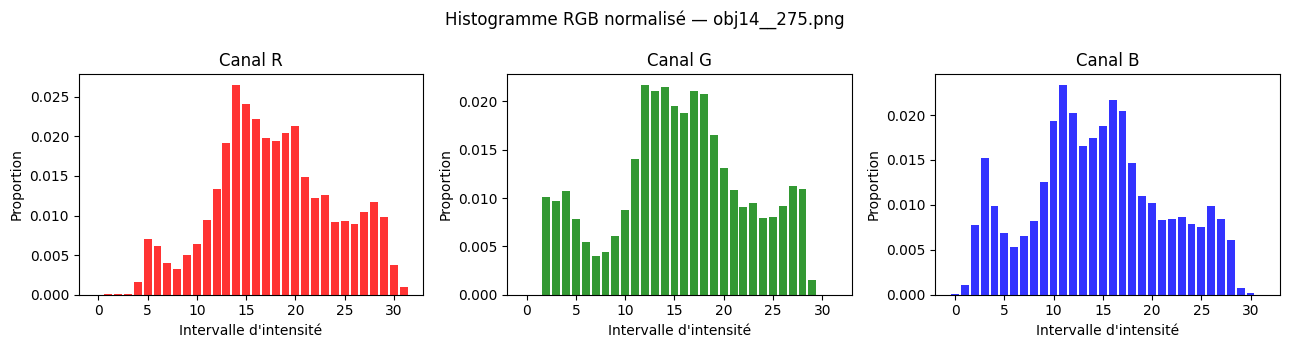

In [3]:
def histogramme_rgb(rgb, masque, bins=BINS):
    """Histogramme RGB normalisé d'une image (pixels d'objet uniquement).

    Retourne un vecteur de longueur 3 * bins : les histogrammes des canaux
    R, G et B concaténés, chacun normalisé, l'ensemble sommant à 1.
    """
    pixels = rgb[masque]                       # (N, 3) : pixels d'objet

    canaux = []
    for c in range(3):
        # np.histogram renvoie les comptes par intervalle sur [0, 256)
        comptes, _ = np.histogram(pixels[:, c], bins=bins, range=(0, 256))
        canaux.append(comptes)

    hist = np.concatenate(canaux).astype(float)

    # Normalisation : somme = 1
    total = hist.sum()
    if total > 0:
        hist = hist / total
    return hist


# --- Test sur une image ---
chemin_test = chemins[0]
rgb_test = charger_image(chemin_test)
masque_test = masque_objet(rgb_test)
hist_test = histogramme_rgb(rgb_test, masque_test)

print(f"Image test      : {os.path.basename(chemin_test)}")
print(f"Longueur du vecteur : {len(hist_test)} (= 3 x {BINS})")
print(f"Somme de l'histogramme : {hist_test.sum():.6f}  (attendu : 1.0)")
print(f"Nombre de bins non vides : {np.count_nonzero(hist_test)} / {len(hist_test)}")

# --- Affichage des 3 canaux ---
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
titres = ["Canal R", "Canal G", "Canal B"]
couleurs = ["red", "green", "blue"]

for c in range(3):
    axes[c].bar(range(BINS), hist_test[c * BINS:(c + 1) * BINS],
                color=couleurs[c], alpha=0.8)
    axes[c].set_title(titres[c])
    axes[c].set_xlabel("Intervalle d'intensité")
    axes[c].set_ylabel("Proportion")

plt.suptitle(f"Histogramme RGB normalisé — {os.path.basename(chemin_test)}")
plt.tight_layout()
plt.savefig(os.path.join(DOSSIER_RESULTATS, "ex2_histogramme_exemple.png"), dpi=120)
plt.show()


## Étape 3 — Intersection d'histogrammes

### Définition

$$\text{inter}(H_1, H_2) = \sum_{i} \min\bigl(H_1(i),\, H_2(i)\bigr)$$

Pour chaque intervalle $i$, on prend le **minimum** des deux proportions : c'est la partie commune aux deux distributions. On additionne ensuite ces minima sur tous les intervalles.

### Propriétés

| Propriété | Valeur |
|---|---|
| Valeur minimale | $0$ (aucun recouvrement) |
| Valeur maximale | $1$ (histogrammes identiques) |
| Symétrie | $\text{inter}(H_1, H_2) = \text{inter}(H_2, H_1)$ |
| Auto-similarité | $\text{inter}(H, H) = 1$ |

L'intersection est **directement une mesure de similarité** : inutile de la convertir, contrairement à la distance de l'exercice 1. On l'exprime souvent en pourcentage : $0{,}75$ = 75 % de recouvrement.

### Interprétation géométrique

L'intersection correspond à l'**aire commune** sous les deux histogrammes. C'est une mesure robuste : elle ne pénalise pas les petites différences locales, contrairement à la distance euclidienne qui est dominée par les bins les plus peuplés.


In [4]:
def intersection_histogrammes(h1, h2):
    """Intersection de deux histogrammes normalisés (similarité dans [0, 1]).

    1.0 = histogrammes identiques, 0.0 = aucun recouvrement.
    """
    return float(np.sum(np.minimum(h1, h2)))


# --- Vérifications ---
hist_a = histogramme_rgb(charger_image(chemins[0]), masque_objet(charger_image(chemins[0])))
hist_b = histogramme_rgb(charger_image(chemins[1]), masque_objet(charger_image(chemins[1])))

print(f"intersection(A, A) = {intersection_histogrammes(hist_a, hist_a):.6f}  (attendu : 1.0)")
print(f"intersection(A, B) = {intersection_histogrammes(hist_a, hist_b):.6f}")
print(f"intersection(B, A) = {intersection_histogrammes(hist_b, hist_a):.6f}  (attendu : identique)")


intersection(A, A) = 1.000000  (attendu : 1.0)
intersection(A, B) = 0.892802
intersection(B, A) = 0.892802  (attendu : identique)


## Étape 4 — Matrice de similarité

On calcule l'intersection pour **toutes les paires** d'images, ce qui donne une matrice de taille $N \times N$ :

- **symétrique** : $\text{inter}(i, j) = \text{inter}(j, i)$ ;
- **diagonale = 1** : chaque image est identique à elle-même ;
- valeurs dans $[0, 1]$.

**Aucune normalisation supplémentaire n'est nécessaire** : l'intersection d'histogrammes normalisés est déjà bornée par 1, contrairement à la distance de l'exercice 1 qui devait être divisée par la distance maximale théorique.


In [5]:
# --- Calcul des histogrammes de toutes les images ---
histogrammes = []
for chemin in chemins:
    rgb = charger_image(chemin)
    masque = masque_objet(rgb)
    histogrammes.append(histogramme_rgb(rgb, masque))

print(f"{len(histogrammes)} histogrammes calculés (longueur {len(histogrammes[0])} chacun).\n")

# --- Matrice d'intersection ---
n = len(chemins)
matrice_similarite = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        matrice_similarite[i, j] = intersection_histogrammes(histogrammes[i], histogrammes[j])

# --- Affichage de la matrice ---
largeur = 16
entete = "Image".ljust(largeur) + "".join(nom[:13].ljust(14) for nom in noms_images)
print(entete)
print("-" * len(entete))
for i, nom in enumerate(noms_images):
    ligne = nom[:15].ljust(largeur)
    ligne += "".join(f"{matrice_similarite[i, j]:.3f}".ljust(14) for j in range(n))
    print(ligne)


12 histogrammes calculés (longueur 96 chacun).

Image           obj14__275.pn obj14__330.pn obj14__60.png obj16__245.pn obj16__5.png  obj16__70.png obj1__180.png obj1__40.png  obj1__95.png  obj27__125.pn obj27__190.pn obj27__275.pn 
----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
obj14__275.png  1.000         0.893         0.839         0.677         0.711         0.761         0.522         0.546         0.547         0.444         0.425         0.410         
obj14__330.png  0.893         1.000         0.887         0.712         0.739         0.792         0.551         0.575         0.576         0.494         0.448         0.463         
obj14__60.png   0.839         0.887         1.000         0.671         0.701         0.731         0.549         0.595         0.590         0.496         0.451         0.480         
obj16__245.png  0.677      

## Étape 5 — Visualisation et comparaison avec l'exercice 1

On produit :

1. La **heatmap** de la matrice d'intersection.
2. Le **classement** des paires les plus similaires.
3. Les **statistiques intra-objet / inter-objets** (même calcul qu'à l'exercice 1).
4. Une **comparaison avec l'exercice 1** : la matrice de similarité de l'exercice 1 est relue depuis `resultats/ex1_matrice_similarite.csv`, puis on affiche la **différence** (ex2 − ex1) et la **corrélation** entre les deux méthodes.

Cette comparaison permet de voir si les deux descripteurs (couleurs dominantes vs histogrammes) classent les images de la même façon.


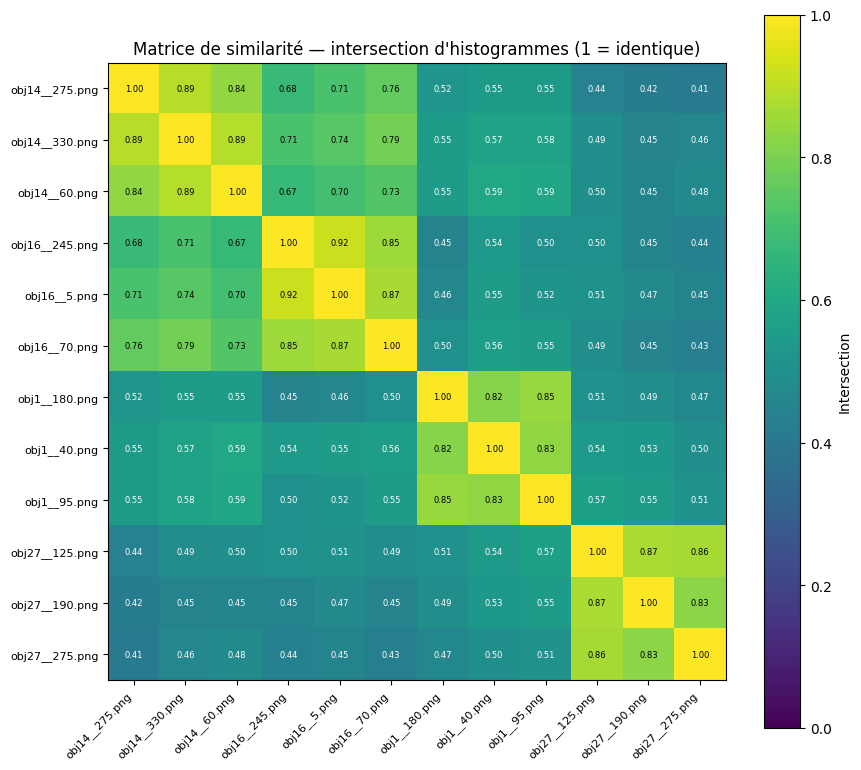

Matrice sauvegardée dans : .\resultats\ex2_matrice_similarite.csv

Les 10 paires d'images les plus similaires :
   1.  92.2 %   obj16__245.png  <->  obj16__5.png
   2.  89.3 %   obj14__275.png  <->  obj14__330.png
   3.  88.7 %   obj14__330.png  <->  obj14__60.png
   4.  87.3 %   obj27__125.png  <->  obj27__190.png
   5.  86.7 %   obj16__5.png  <->  obj16__70.png
   6.  86.3 %   obj27__125.png  <->  obj27__275.png
   7.  85.2 %   obj16__245.png  <->  obj16__70.png
   8.  84.7 %   obj1__180.png  <->  obj1__95.png
   9.  83.9 %   obj14__275.png  <->  obj14__60.png
  10.  83.5 %   obj1__40.png  <->  obj1__95.png

Similarité moyenne à l'intérieur d'un objet vs meilleure similarité externe
Objet      intra (moy.)   externe (max)      écart
obj1              0.833           0.595     +0.238
obj14             0.873           0.792     +0.080
obj16             0.880           0.792     +0.088
obj27             0.855           0.566     +0.289


In [6]:
# --- Heatmap de la matrice d'intersection ---
fig, ax = plt.subplots(figsize=(9, 8))
image = ax.imshow(matrice_similarite, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(n))
ax.set_yticks(range(n))
ax.set_xticklabels(noms_images, rotation=45, ha="right", fontsize=8)
ax.set_yticklabels(noms_images, fontsize=8)
ax.set_title("Matrice de similarité — intersection d'histogrammes (1 = identique)")
fig.colorbar(image, ax=ax, label="Intersection")

for i in range(n):
    for j in range(n):
        ax.text(j, i, f"{matrice_similarite[i, j]:.2f}", ha="center", va="center",
                fontsize=6, color="white" if matrice_similarite[i, j] < 0.6 else "black")

plt.tight_layout()
plt.savefig(os.path.join(DOSSIER_RESULTATS, "ex2_matrice_similarite.png"), dpi=130)
plt.show()

# --- Sauvegarde CSV ---
chemin_csv = os.path.join(DOSSIER_RESULTATS, "ex2_matrice_similarite.csv")
with open(chemin_csv, "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["Image"] + noms_images)
    for i, nom in enumerate(noms_images):
        writer.writerow([nom] + [f"{matrice_similarite[i, j]:.6f}" for j in range(n)])
print(f"Matrice sauvegardée dans : {chemin_csv}\n")

# --- Classement des paires les plus similaires ---
paires = []
for i in range(n):
    for j in range(i + 1, n):
        paires.append((matrice_similarite[i, j], noms_images[i], noms_images[j]))
paires.sort(reverse=True)

print("Les 10 paires d'images les plus similaires :")
for rang, (sim, a, b) in enumerate(paires[:10], start=1):
    print(f"  {rang:2d}. {sim * 100:5.1f} %   {a}  <->  {b}")

# --- Statistiques intra-objet / inter-objets ---
groupes = [nom.split("__")[0] for nom in noms_images]

print("\n" + "=" * 78)
print("Similarité moyenne à l'intérieur d'un objet vs meilleure similarité externe")
print("=" * 78)
print(f"{'Objet':8s} {'intra (moy.)':>14s} {'externe (max)':>15s} {'écart':>10s}")
for groupe in sorted(set(groupes)):
    dedans = [i for i, g in enumerate(groupes) if g == groupe]
    dehors = [i for i, g in enumerate(groupes) if g != groupe]

    intra = np.mean([matrice_similarite[i, j] for i in dedans for j in dedans if i < j])
    externe = matrice_similarite[np.ix_(dedans, dehors)].max()

    print(f"{groupe:8s} {intra:14.3f} {externe:15.3f} {intra - externe:+10.3f}")


Comparaison des deux méthodes (hors diagonale)
Similarité moyenne — couleurs dominantes (ex1) : 0.569
Similarité moyenne — histogrammes       (ex2) : 0.598

Corrélation de Pearson entre les deux matrices : 0.788


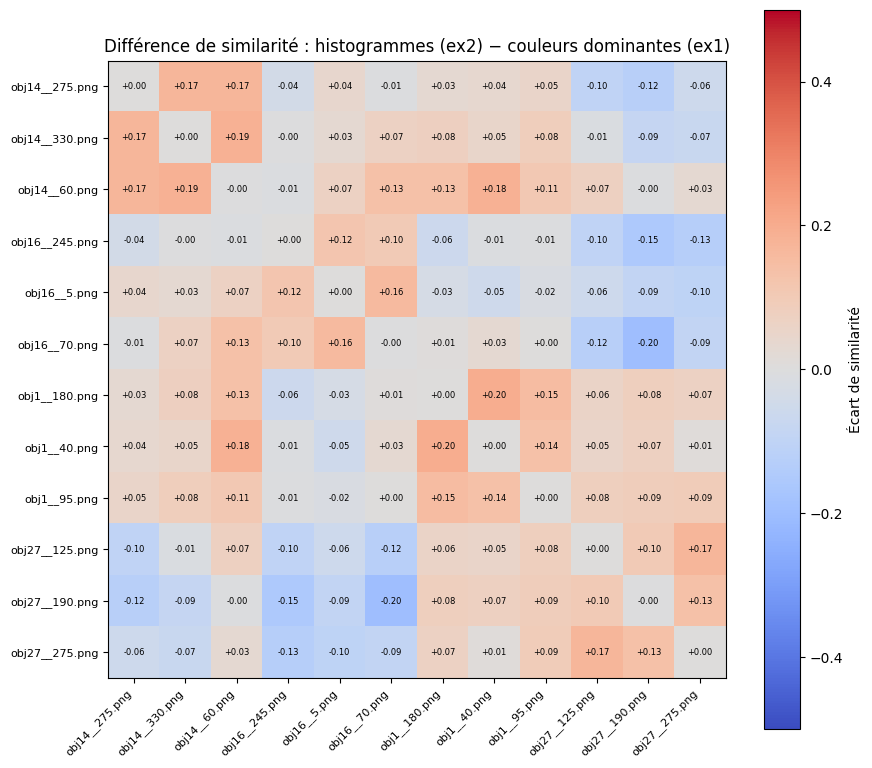


Paires où les histogrammes sont BEAUCOUP plus généreux que les couleurs dominantes :
  +0.197   obj1__180.png  <->  obj1__40.png   (ex1 = 0.621, ex2 = 0.818)
  +0.187   obj14__330.png  <->  obj14__60.png   (ex1 = 0.700, ex2 = 0.887)
  +0.184   obj14__60.png  <->  obj1__40.png   (ex1 = 0.410, ex2 = 0.595)
  +0.170   obj27__125.png  <->  obj27__275.png   (ex1 = 0.693, ex2 = 0.863)
  +0.170   obj14__275.png  <->  obj14__330.png   (ex1 = 0.723, ex2 = 0.893)

Paires où les histogrammes sont BEAUCOUP plus sévères que les couleurs dominantes :
  -0.122   obj14__275.png  <->  obj27__190.png   (ex1 = 0.547, ex2 = 0.425)
  -0.125   obj16__70.png  <->  obj27__125.png   (ex1 = 0.618, ex2 = 0.493)
  -0.132   obj16__245.png  <->  obj27__275.png   (ex1 = 0.572, ex2 = 0.440)
  -0.154   obj16__245.png  <->  obj27__190.png   (ex1 = 0.607, ex2 = 0.453)
  -0.197   obj16__70.png  <->  obj27__190.png   (ex1 = 0.643, ex2 = 0.445)


In [7]:
# --- Comparaison avec l'exercice 1 ---
# On relit la matrice de similarité de l'exercice 1 (couleurs dominantes).
chemin_ex1 = os.path.join(DOSSIER_RESULTATS, "ex1_matrice_similarite.csv")

if os.path.exists(chemin_ex1):
    with open(chemin_ex1, newline="", encoding="utf-8") as f:
        lignes = list(csv.reader(f))

    noms_ex1 = lignes[0][1:]                       # noms d'images en en-tête
    matrice_ex1 = np.array([[float(v) for v in ligne[1:]] for ligne in lignes[1:]])

    # On réordonne la matrice de l'exercice 1 selon l'ordre courant des images
    ordre = [noms_ex1.index(nom) for nom in noms_images]
    matrice_ex1 = matrice_ex1[np.ix_(ordre, ordre)]

    # --- Différence entre les deux méthodes (hors diagonale) ---
    difference = matrice_similarite - matrice_ex1
    masque_hors_diag = ~np.eye(n, dtype=bool)

    print("=" * 78)
    print("Comparaison des deux méthodes (hors diagonale)")
    print("=" * 78)
    print(f"Similarité moyenne — couleurs dominantes (ex1) : {matrice_ex1[masque_hors_diag].mean():.3f}")
    print(f"Similarité moyenne — histogrammes       (ex2) : {matrice_similarite[masque_hors_diag].mean():.3f}")

    # Corrélation de Pearson entre les deux matrices
    x = matrice_ex1[masque_hors_diag]
    y = matrice_similarite[masque_hors_diag]
    correlation = np.corrcoef(x, y)[0, 1]
    print(f"\nCorrélation de Pearson entre les deux matrices : {correlation:.3f}")

    # --- Heatmap de la différence ---
    fig, ax = plt.subplots(figsize=(9, 8))
    image = ax.imshow(difference, cmap="coolwarm", vmin=-0.5, vmax=0.5)
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels(noms_images, rotation=45, ha="right", fontsize=8)
    ax.set_yticklabels(noms_images, fontsize=8)
    ax.set_title("Différence de similarité : histogrammes (ex2) − couleurs dominantes (ex1)")
    fig.colorbar(image, ax=ax, label="Écart de similarité")

    for i in range(n):
        for j in range(n):
            ax.text(j, i, f"{difference[i, j]:+.2f}", ha="center", va="center",
                    fontsize=6, color="black")

    plt.tight_layout()
    plt.savefig(os.path.join(DOSSIER_RESULTATS, "ex2_comparaison_ex1.png"), dpi=130)
    plt.show()

    # --- Paires dont le classement change le plus ---
    ecarts = []
    for i in range(n):
        for j in range(i + 1, n):
            ecarts.append((difference[i, j], noms_images[i], noms_images[j],
                           matrice_ex1[i, j], matrice_similarite[i, j]))
    ecarts.sort(reverse=True)

    print("\nPaires où les histogrammes sont BEAUCOUP plus généreux que les couleurs dominantes :")
    for ecart, a, b, s1, s2 in ecarts[:5]:
        print(f"  {ecart:+.3f}   {a}  <->  {b}   (ex1 = {s1:.3f}, ex2 = {s2:.3f})")

    print("\nPaires où les histogrammes sont BEAUCOUP plus sévères que les couleurs dominantes :")
    for ecart, a, b, s1, s2 in ecarts[-5:]:
        print(f"  {ecart:+.3f}   {a}  <->  {b}   (ex1 = {s1:.3f}, ex2 = {s2:.3f})")
else:
    print(f"Fichier '{chemin_ex1}' introuvable : exécutez d'abord l'exercice 1.")


## Étape 6 — Analyse et discussion

### Résultats obtenus

**Paires les plus similaires :**

| Rang | Intersection | Paire |
|---|---|---|
| 1 | 92.2 % | `obj16__245` ↔ `obj16__5` |
| 2 | 89.3 % | `obj14__275` ↔ `obj14__330` |
| 3 | 88.7 % | `obj14__330` ↔ `obj14__60` |
| 4 | 87.3 % | `obj27__125` ↔ `obj27__190` |
| 5 | 86.7 % | `obj16__5` ↔ `obj16__70` |
| 6 | 86.3 % | `obj27__125` ↔ `obj27__275` |
| 7 | 85.2 % | `obj16__245` ↔ `obj16__70` |
| 8 | 84.7 % | `obj1__180` ↔ `obj1__95` |

**Les 8 premières paires appartiennent toutes au même objet.** C'est une amélioration nette par rapport à l'exercice 1, où la 3ᵉ paire était déjà une confusion inter-objets.

**Similarité intra-objet vs meilleure similarité externe :**

| Objet | Intra (moy.) | Externe (max) | Écart |
|---|---|---|---|
| `obj1` (boîte jaune) | 0.833 | 0.595 | **+0.238** |
| `obj14` (chat blanc) | 0.873 | 0.792 | **+0.080** |
| `obj16` (pot blanc) | 0.880 | 0.792 | **+0.088** |
| `obj27` (voiture verte) | 0.855 | 0.566 | **+0.289** |

**L'écart est positif pour les quatre objets**, alors qu'il était négatif pour `obj14` et `obj16` avec les couleurs dominantes. La heatmap montre quatre blocs 4×4 bien délimités.

### Interprétation

1. **Séparation correcte de tous les objets.** L'intersection d'histogrammes distingue maintenant le chat blanc (`obj14`) du pot blanc (`obj16`), ce que les couleurs dominantes ne parvenaient pas à faire. La raison : l'histogramme conserve **toute la distribution**, y compris les teintes minoritaires (collier rouge du chat, fleurs colorées du pot) qui disparaissaient dans les 10 couleurs dominantes.

2. **`obj1` et `obj27` sont les mieux séparés** (+0.238 et +0.289) : leur distribution de couleurs est très typée (jaune/orangé, vert).

3. **`obj14` et `obj16` restent les plus proches** (+0.080 et +0.088) : ils partagent effectivement une grande surface blanche. La confusion est réduite mais pas éliminée — la paire `obj14__330` ↔ `obj16__70` atteint encore 0.792.

4. **Comparaison avec l'exercice 1** :
   - Similarité moyenne : 0.569 (ex1) contre 0.598 (ex2) — les histogrammes sont légèrement plus généreux, mais surtout **mieux ordonnés**.
   - **Corrélation de Pearson : 0.788** — les deux méthodes s'accordent globalement, mais pas parfaitement.
   - Les histogrammes sont **beaucoup plus généreux** pour les paires du même objet : `obj1__180`↔`obj1__40` (+0.197), `obj14__330`↔`obj14__60` (+0.187), `obj27__125`↔`obj27__275` (+0.170). C'est exactement le comportement souhaité.
   - Ils sont **plus sévères** pour les paires inter-objets, en particulier `obj16` ↔ `obj27` (jusqu'à −0.197) : la voiture verte et le pot blanc ont des distributions très différentes, ce que les couleurs dominantes ne pénalisaient pas assez.

5. **La normalisation par le nombre de pixels d'objet est essentielle** : sans elle, `obj27__275` (85 % d'objet) dominerait toutes les comparaisons face à `obj27__190` (25 % d'objet).

### Limites de la méthode

1. **Perte de l'information spatiale** : l'histogramme global ignore la position des couleurs. Un objet blanc sur fond rouge et l'inverse donnent le même histogramme.
2. **Sensibilité au nombre de bins** : avec `BINS = 256`, la plupart des bins seraient vides sur des images 128×128 et l'intersection chuterait artificiellement. Avec `BINS = 8`, toutes les teintes seraient fusionnées.
3. **Sensibilité au masque du fond** : une erreur de masquage introduit un pic parasite dans l'histogramme.
4. **Éclairage** : une variation de luminosité décale l'histogramme d'un canal et réduit le recouvrement.
5. **Objets bicolores** : deux objets partageant deux couleurs dans des proportions similaires mais disposées différemment resteraient confondus.

### Améliorations possibles

- **Histogramme par blocs** (grille 4×4, comme en séance 3) pour réintroduire l'information spatiale.
- Passer en espace **HSV** et pondérer les canaux différemment (la teinte est plus discriminante que la luminosité).
- Utiliser **plusieurs métriques** (intersection, chi², Bhattacharyya) et comparer, comme dans le script de la séance 3.
- Combiner les deux exercices : intersection d'histogrammes **et** couleurs dominantes pour un descripteur plus robuste.

### Conclusion

L'intersection d'histogrammes **surpasse les couleurs dominantes** sur ce jeu d'images : les quatre objets sont correctement séparés (écart intra/inter positif partout), et les huit paires les plus similaires appartiennent toutes à un même objet. La corrélation de 0.788 avec l'exercice 1 confirme que les deux méthodes capturent la même information de base, mais l'histogramme exploite mieux les couleurs minoritaires. La limite commune reste l'**absence d'information spatiale**, ce qui motive l'utilisation de la texture de Tamura dans l'exercice 3.
